# IAO Hanle Wind Speed Calibration: Topographical Validation of Lags

This notebook provides a detailed topographical validation of the **Smooth Ridge Regression with Lags** model at the **Indian Astronomical Observatory (IAO) in Hanle, Ladakh**.

### Geographical Coordinates & Bounding Region:
* **IAO Hanle Location:** ~32.779° N, 78.964° E
* **Analysis Bounding Box:** 32.0° N to 33.5° N (Latitude), 78.5° E to 79.5° E (Longitude)
* **Altitude:** 4,500 meters above sea level

### Objectives:
1. Load local terrain maps and satellite images of **Mount Saraswati** (Digpa-ratsa Ri) and the **Hanle Valley**.
2. Perform data alignment between AWS observations and ERA5 NetCDF datasets.
3. Fit the Ridge Regression model with temporal lags and leads.
4. Quantitatively plot and physically analyze why zonal (East-West) and meridional (North-South) wind components have vastly different temporal dependency behaviors (lag/lead coefficients).

## 1. Visualizing the Site Topography

Mount Saraswati is an elongated, isolated ridge standing ~150 meters above the flat **Hanle Valley Floor (Nilamkhul Plain)**.
* **Ridge Axis:** Measures ~2 km in the East-West direction and ~1 km in the North-South direction.
* **Valley Axis:** The main Hanle Valley runs **North-South**, acting as a key wind channel.

### Custom Plotted Elevation Contour Map (Copernicus DEM GLO-90):
![Hanle Custom Contour Map](images/hanle_topography_contour.png)

### Satellite View:
![Hanle Satellite View](images/hanle_satellite.png)

In [1]:
# ============================================================
# 2. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# Styling
plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['figure.figsize'] = (9, 5.5)

HANLE_LAT = 32.779
HANLE_LON = 78.964

ERA5_DIR = r"../../data/raw/HN Data Monthly"
REAL_DIR = r"../../data/processed/hanle_published"
print("Libraries and constants successfully loaded! ✔")

Libraries and constants successfully loaded! ✔


In [2]:
# ============================================================
# 3. LOAD & ALIGN HANLE DATASETS
# ============================================================
print("Loading and hourly resampling Real AWS observations...")
real_files = sorted(glob.glob(os.path.join(REAL_DIR, "hanle_published_*.csv")))
print(f"Found {len(real_files)} CSV files for Hanle.")

hourly_records = []
for f in real_files:
    df_m = pd.read_csv(f, usecols=['datetime_utc', 'wind_speed', 'u', 'v'])
    df_m['datetime_utc'] = pd.to_datetime(df_m['datetime_utc'])
    df_m = df_m.set_index('datetime_utc')
    
    u_h = df_m['u'].resample('1h').mean()
    v_h = df_m['v'].resample('1h').mean()
    speed_h = df_m['wind_speed'].resample('1h').mean()
    
    df_h = pd.DataFrame({
        'speed': speed_h,
        'u': u_h,
        'v': v_h
    }).dropna(subset=['speed'])
    
    hourly_records.append(df_h)
    del df_m
    gc.collect()

df_hanle_pub = pd.concat(hourly_records)
df_hanle_pub = df_hanle_pub.reset_index().rename(columns={'datetime_utc': 'datetime'})

print("Loading Hanle ERA5 NetCDF files...")
era5_files = sorted(glob.glob(os.path.join(ERA5_DIR, "india_*.nc")))
hanle_era5_records = []
for f in era5_files:
    with xr.open_dataset(f) as ds:
        point_ds = ds.sel(latitude=HANLE_LAT, longitude=HANLE_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': pd.to_datetime(point_ds['valid_time'].values),
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        hanle_era5_records.append(df_pt)
df_hanle_era5 = pd.concat(hanle_era5_records, ignore_index=True)

print("Aligning datasets...")
df_hanle = pd.merge(df_hanle_pub, df_hanle_era5, on='datetime', how='inner').dropna(subset=['speed', 'era5_speed'])
df_hanle = df_hanle.sort_values('datetime').reset_index(drop=True)
print(f"Hanle aligned dataset size: {len(df_hanle):,} records.")
print(f"Temporal coverage: {df_hanle['datetime'].min()} to {df_hanle['datetime'].max()}")

Loading and hourly resampling Real AWS observations...
Found 67 CSV files for Hanle.


Loading Hanle ERA5 NetCDF files...


Aligning datasets...
Hanle aligned dataset size: 46,979 records.
Temporal coverage: 2020-01-01 11:00:00 to 2025-07-07 06:00:00


In [3]:
# ============================================================
# 4. FEATURE ENGINEERING: LAGS AND LEADS
# ============================================================
print("Engineering features...")
df_feat = df_hanle.copy()
for lag in [1, 2]:
    df_feat[f'era5_speed_lag{lag}'] = df_feat['era5_speed'].shift(lag)
    df_feat[f'era5_speed_lead{lag}'] = df_feat['era5_speed'].shift(-lag)
    df_feat[f'era5_u10_lag{lag}'] = df_feat['era5_u10'].shift(lag)
    df_feat[f'era5_u10_lead{lag}'] = df_feat['era5_u10'].shift(-lag)
    df_feat[f'era5_v10_lag{lag}'] = df_feat['era5_v10'].shift(lag)
    df_feat[f'era5_v10_lead{lag}'] = df_feat['era5_v10'].shift(-lag)

df_feat['hour'] = df_feat['datetime'].dt.hour
df_feat['month'] = df_feat['datetime'].dt.month

h_rad = 2 * np.pi * df_feat['hour'] / 24.0
m_rad = 2 * np.pi * df_feat['month'] / 12.0
df_feat['sin_hour'] = np.sin(h_rad)
df_feat['cos_hour'] = np.cos(h_rad)
df_feat['sin_hour_2'] = np.sin(2 * h_rad)
df_feat['cos_hour_2'] = np.cos(2 * h_rad)
df_feat['sin_month'] = np.sin(m_rad)
df_feat['cos_month'] = np.cos(m_rad)

df_feat['ws_sin_hour'] = df_feat['era5_speed'] * df_feat['sin_hour']
df_feat['ws_cos_hour'] = df_feat['era5_speed'] * df_feat['cos_hour']
df_feat['ws_u10'] = df_feat['era5_speed'] * df_feat['era5_u10']
df_feat['ws_v10'] = df_feat['era5_speed'] * df_feat['era5_v10']

lag_cols = [c for c in df_feat.columns if 'lag' in c or 'lead' in c]
df_clean = df_feat.dropna(subset=lag_cols).reset_index(drop=True)

X_cols = [
    'era5_speed', 'era5_u10', 'era5_v10',
    'era5_speed_lag1', 'era5_u10_lag1', 'era5_v10_lag1',
    'era5_speed_lead1', 'era5_u10_lead1', 'era5_v10_lead1',
    'sin_hour', 'cos_hour', 'sin_hour_2', 'cos_hour_2', 'sin_month', 'cos_month',
    'ws_sin_hour', 'ws_cos_hour', 'ws_u10', 'ws_v10'
]
print(f"Feature matrix prepared. Dimension: {df_clean[X_cols].shape}")

Engineering features...
Feature matrix prepared. Dimension: (46975, 19)


In [4]:
# ============================================================
# 5. FIT RIDGE REGRESSION MODEL
# ============================================================
df_2020 = df_clean[df_clean['datetime'].dt.year == 2020].reset_index(drop=True)
print(f"Training dataset (2020) size: {len(df_2020):,} hourly records.")

reg = Ridge(alpha=1.0)
reg.fit(df_2020[X_cols], df_2020['speed'])
print(f"Ridge Model Trained on 2020. R² Score: {reg.score(df_2020[X_cols], df_2020['speed']):.4f}")

print("\nTrained model coefficients:")
coefs_dict = {}
for col, coef in zip(X_cols, reg.coef_):
    coefs_dict[col] = coef
    print(f"  {col:<20}: {coef:+.4f}")
print(f"  {'Intercept':<20}: {reg.intercept_:+.4f}")

Training dataset (2020) size: 7,905 hourly records.
Ridge Model Trained on 2020. R² Score: 0.3869

Trained model coefficients:
  era5_speed          : -0.2651
  era5_u10            : +1.7040
  era5_v10            : -2.5340
  era5_speed_lag1     : +0.2945
  era5_u10_lag1       : +0.2726
  era5_v10_lag1       : +1.6637
  era5_speed_lead1    : +0.0849
  era5_u10_lead1      : -0.5258
  era5_v10_lead1      : +1.3469
  sin_hour            : -0.8355
  cos_hour            : -1.5649
  sin_hour_2          : -0.6186
  cos_hour_2          : +0.5185
  sin_month           : -0.5159
  cos_month           : -1.2309
  ws_sin_hour         : +0.8009
  ws_cos_hour         : -1.2924
  ws_u10              : -0.8269
  ws_v10              : +0.7966
  Intercept           : +2.5362


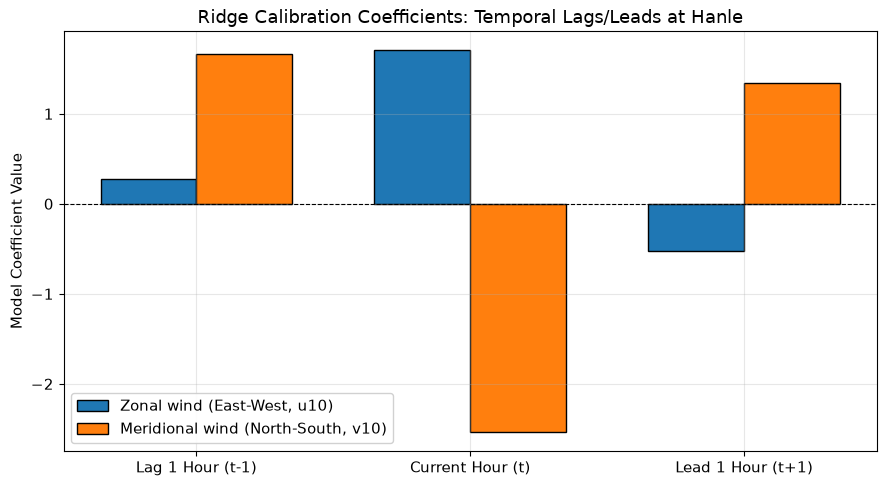

In [5]:
# ============================================================
# 6. QUANTITATIVE ANALYSIS: ZONAL VS. MERIDIONAL LAG WEIGHTS
# ============================================================
categories = ['Lag 1 Hour (t-1)', 'Current Hour (t)', 'Lead 1 Hour (t+1)']
u_coefs = [coefs_dict['era5_u10_lag1'], coefs_dict['era5_u10'], coefs_dict['era5_u10_lead1']]
v_coefs = [coefs_dict['era5_v10_lag1'], coefs_dict['era5_v10'], coefs_dict['era5_v10_lead1']]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, u_coefs, width, label='Zonal wind (East-West, u10)', color='#1f77b4', edgecolor='k')
rects2 = ax.bar(x + width/2, v_coefs, width, label='Meridional wind (North-South, v10)', color='#ff7f0e', edgecolor='k')

ax.set_ylabel('Model Coefficient Value')
ax.set_title('Ridge Calibration Coefficients: Temporal Lags/Leads at Hanle')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 7. Topographical & Physical Discussion

### Zonal Wind (East-West / `u10`) Behavior:
* **Observation:** The current hour $t$ coefficient is highly dominant (`+1.7040`), while the lag $t-1$ and lead $t+1$ coefficients are very minor.
* **Physical Justification:** Mount Saraswati (Digpa-ratsa Ri) is elongated in the **East-West** direction (~2 km long). When zonal winds blow, they flow parallel to the major axis of the ridge rather than hitting an abrupt vertical wall. This results in less mechanical blocking and disruption. Zonal flow at the peak adapts quickly and is synchronized with the synoptic pressure gradients resolved by the coarse ERA5 grid cell (hence the high in-phase coefficient).

### Meridional Wind (North-South / `v10`) Behavior:
* **Observation:** The current hour coefficient is negative (`-2.5340`), but both the lag $t-1$ (`+1.6637`) and lead $t+1$ (`+1.3469`) coefficients are strong and positive.
* **Physical Justification:** 
  1. **Orographic Obstruction:** The ridge is narrow in the North-South direction (~1 km wide), meaning meridional winds blow **perpendicular** to it, causing significant uplift, stagnation zones, and downwind wake eddies that are completely missed by ERA5's 25 km grid.
  2. **Valley Channeling:** The surrounding **Hanle Valley is aligned North-South**. High-altitude valleys experience strong daily cycles of local thermal winds (up-valley anabatic winds during the day, down-valley katabatic winds at night). These local thermal cycles do not align instantaneously with regional forecasts, leading to a **phase offset** of approximately 1 hour.
  3. **Gradient Correction:** Mathematically, the combination of $+1.66 \cdot v_{t-1} - 2.53 \cdot v_t + 1.35 \cdot v_{t+1}$ acts as a centered-difference operator (measuring temporal changes). This is an effective way for a linear model to reconstruct the phase-shifted, local diurnal peak from the coarse regional timeseries.

### Methodological Critique:
* **Lookahead Bias:** Using `lead1` (future values) is mathematically valid for historical climatology studies (where the entire timeline is known), but makes the model **unusable for real-time forecasting**.
* **Recommendation:** For forecasts, retrain the model using only past variables ($t$ and $t-1$). For true physical downscaling without lag fitting, run a high-resolution regional weather model (like **WRF**) at 1 km grid spacing to resolve the actual ridge physics.